#### Цель
Превратить исследование из частей I–II в отдельный ML-проект. Добавить SVM и Naive Bayes. Запишем в документации ограничения модели ранней поддержки: временные (какие данные известны при поступлении) и этические (как прогноз можно и нельзя использовать).
#### Что сдать
* Репозиторий student-outcome-classification/, ветка clf/students_dropout/part_3.
* Код в модулях src/ и скрипт или CLI для запуска обучения.
* Unit-тесты в tests/, которые работают без сети.
* README.md с инструкцией запуска, результатами, правилом отбора признаков и разделом ограничений.
* На чистой машине проходят uv sync, uv run ruff check ., uv run ruff format --check . и uv run pytest.
#### Входные артефакты
Структура репозитория student-outcome-classification/: src/, notebooks/, tests/, README.md, pyproject.toml, uv.lock и .gitignore. Все части можно вести в нём: результаты частей I–III лежат на ветках clf/students_dropout/part_1, clf/students_dropout/part_2 и clf/students_dropout/part_3.  
Загружай данные по официальной ссылке UCI (ссылка https://archive.ics.uci.edu/dataset/697/predict%20students%20dropout%20and%20academic%20success ) или принимай путь к локальному файлу. Исходную таблицу не коммить.  
Пропиши в коде allowlist признаков на момент поступления и запрет всех показателей первого и второго семестров.
#### Шаг 1. Архитектура
* Вынеси в отдельные модули src/: загрузку данных и проверку схемы, составление allowlist, preprocessing, обучение, оценку и сохранение результатов.
* Добавь CLI (запуск из командной строки) или скрипт обучения с фиксированным seed.
* Пути к данным и результатам задавай через конфигурацию, а не прямо в коде.
#### Шаг 2. SVM и Naive Bayes
* Сравни SVM минимум с двумя ядрами: линейным и RBF. Перед этим масштабируй нужные признаки.
* Выбери вариант Naive Bayes и объясни выбор. Например, GaussianNB — для непрерывных признаков, CategoricalNB — после корректного кодирования категорий.
* Не считай числовые коды категорий непрерывной шкалой без обоснования.
#### Шаг 3. Сравнение
* Оцени по одной схеме split/CV: SVM, Naive Bayes, логистическую регрессию, дерево, случайный лес, градиентный бустинг, XGBoost, LightGBM и CatBoost.
* Выбирай итоговую модель по macro F1.
* Обязательно покажи метрики по каждому классу, weighted F1, balanced accuracy и матрицу ошибок.
#### Шаг 4. Тесты
Напиши unit-тесты, которые проверяют:
* проверку схемы данных (нужные столбцы и типы);
* составление allowlist;
* что семестровые признаки и целевая переменная исключены;
* что pipeline обучается на маленьком искусственном наборе данных.

Тесты не должны зависеть от сети и скачивания датасета.
#### Шаг 5. README
* Опиши источник и лицензию данных, установку через uv, команды обучения и тестов, структуру проекта и таблицу результатов.
* Опиши temporal feature policy (правило: в модель идут только признаки, известные при поступлении).
* Отдельным разделом опиши ограничения. Чувствительные демографические признаки могут усиливать несправедливость. Модель нужна, чтобы предлагать добровольную поддержку. Она не должна автоматически решать вопросы о санкциях, доступе к образованию или судьбе конкретного студента.
#### Шаг 6. Качество кода
На чистой машине должны проходить:
* uv sync
* uv run ruff check .
* uv run ruff format --check .
* uv run pytest

#### 1. Правило отбора признаков
15 категориальных + 3 числовых поля. Все 12 семестровых показателей запрещены. Также исключены Debtor, Tuition fees up to date, Scholarship holder и три макропоказателя: нет подтверждённого снимка их значений на момент поступления. Смысловые коды Unknown сохраняются как категории. Новые поля не расширяют allowlist автоматически.

In [1]:
# Фиксируем политику признаков из части I
import pandas as pd

FEATURE_SPEC = [
    ("Marital status", "category", "Семейное положение из анкеты; код не является числом на шкале"),
    ("Application mode", "category", "Способ поступления известен при оформлении"),
    (
        "Application order",
        "category",
        "Приоритет программы в заявлении; интервалы не считаем равными",
    ),
    (
        "Course",
        "category",
        "Программа, на которую поступил студент; число является идентификатором",
    ),
    ("Daytime/evening attendance", "category", "Выбранная дневная или вечерняя форма"),
    (
        "Previous qualification",
        "category",
        "Предыдущее образование; коды не образуют числовую шкалу",
    ),
    ("Previous qualification (grade)", "numeric", "Оценка предыдущего образования, шкала 0–200"),
    ("Nacionality", "category", "Гражданство из анкеты; сохранено исходное написание UCI"),
    ("Mother's qualification", "category", "Образование матери из анкеты; номинальные коды"),
    ("Father's qualification", "category", "Образование отца из анкеты; номинальные коды"),
    ("Mother's occupation", "category", "Профессия матери, указанная при поступлении"),
    ("Father's occupation", "category", "Профессия отца, указанная при поступлении"),
    ("Admission grade", "numeric", "Вступительный балл, шкала 0–200"),
    ("Displaced", "category", "Анкетный статус переезда к месту обучения на дату поступления"),
    (
        "Educational special needs",
        "category",
        "Заявленные при поступлении особые образовательные потребности",
    ),
    ("Gender", "category", "Пол, записанный в анкете; коды UCI"),
    ("Age at enrollment", "numeric", "Возраст непосредственно при поступлении"),
    ("International", "category", "Международный статус при поступлении"),
]
ALLOWLIST = [row[0] for row in FEATURE_SPEC]
CATEGORICAL = [row[0] for row in FEATURE_SPEC if row[1] == "category"]
NUMERIC = [row[0] for row in FEATURE_SPEC if row[1] == "numeric"]
UNCERTAIN = [
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]
CLASSES = ["Dropout", "Enrolled", "Graduate"]


def select_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Выбери только разрешённые признаки в фиксированном порядке.

    Args:
        frame: Таблица с анкетными полями; дополнительные столбцы игнорируются.

    Returns:
        Независимая копия 18 признаков.

    Raises:
        ValueError: Если отсутствует обязательный признак.
    """
    missing = set(ALLOWLIST) - set(frame.columns)
    if missing:
        raise ValueError(f"Missing features: {sorted(missing)}")
    return frame.loc[:, ALLOWLIST].copy()

#### 2. Загрузка и контракт данных
Числовой тип хранения категории проверяем отдельно от ее смысла. NaN признаков обрабатываются внутри folds; неизвестная или пустая цель недопустима.

In [2]:
# Загрузим UCI CSV и проверим контракт обучающей таблицы.
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
from pandas.api.types import is_numeric_dtype

DATA_URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"


def validate_schema(frame: pd.DataFrame) -> None:
    """Проверь обязательные поля, типы, цель и допустимые диапазоны.

    Args:
        frame: Непустая таблица после удаления пробелов в заголовках.

    Raises:
        ValueError: Если нарушена схема; NaN разрешены только в признаках.
    """
    if frame.empty or not frame.columns.is_unique:
        raise ValueError("Empty table or duplicate columns")
    missing = set(ALLOWLIST + ["Target"]) - set(frame.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    for name in ALLOWLIST:
        series = frame[name]
        if not is_numeric_dtype(series) or series.dtype == bool:
            raise ValueError(f"Numeric storage required: {name}")
        values = series.dropna().to_numpy(dtype=float)
        if not np.isfinite(values).all():
            raise ValueError(f"Non-finite values: {name}")
        if name in CATEGORICAL and ((values < 0).any() or (values % 1 != 0).any()):
            raise ValueError(f"Nonnegative integer category required: {name}")
    for name in ["Admission grade", "Previous qualification (grade)"]:
        if not frame[name].dropna().between(0, 200).all():
            raise ValueError(f"Grade out of range: {name}")
    if not frame["Age at enrollment"].dropna().between(10, 100).all():
        raise ValueError("Age out of range")
    target = frame["Target"]
    if target.isna().any() or set(target.unique()) != set(CLASSES):
        raise ValueError("Training target must contain exactly three UCI classes")


def load_data(path: Path, download: bool = False) -> pd.DataFrame:
    """Прочитай локальный CSV; скачай официальный архив только по запросу.

    Args:
        path: Путь к CSV с разделителем ';'.
        download: Разрешение загрузить отсутствующий файл из UCI.

    Returns:
        Проверенная таблица с нормализованными заголовками.

    Raises:
        FileNotFoundError: Если CSV отсутствует и загрузка выключена.
        ValueError: Если схема неверна.
    """
    if not path.exists() and download:
        with urlopen(DATA_URL, timeout=60) as response:
            payload = response.read()
        with ZipFile(BytesIO(payload)) as archive:
            data = archive.read("data.csv")
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(data)
    frame = pd.read_csv(path, sep=";")
    frame.columns = frame.columns.str.strip()
    validate_schema(frame)
    return frame

#### 3. Preprocessing и выбор Naive Bayes
Для SVM, LR, деревьев и бустингов: one-hot для кодов категорий, StandardScaler для трёх числовых полей. Масштабирование деревьям не нужно, но сохраняем единый preprocessing. CatBoost здесь получает one-hot, без нативного categorical режима.  

Для CategoricalNB: OrdinalEncoder даёт категории, а не непрерывную шкалу. Неизвестный код -1 сдвигается в 0; известные коды начинаются с 1. Нулевая категория резервируется сглаживанием. Числовые признаки разбиваем на 5 равномерных интервалов, границы обучаются только на train-fold. Это теряет часть числовой информации, зато не предполагает нормального распределения бинарных one-hot признаков, как GaussianNB. Условная независимость признаков - сильное и заведомо приблизительное допущение.

In [3]:
# Соберем преобразования, обучаемые отдельно внутри каждого fold.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    KBinsDiscretizer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)


def shift_categories(values: np.ndarray) -> np.ndarray:
    """Зарезервируй нулевой код для неизвестной категории.

    Args:
        values: Коды OrdinalEncoder, где неизвестная категория равна -1.

    Returns:
        Неотрицательные целочисленные коды.
    """
    return (values + 1).astype(np.int64)


def make_preprocessor(naive_bayes: bool = False) -> ColumnTransformer:
    """Создай независимый preprocessing для смешанных признаков.

    Args:
        naive_bayes: Использовать категории и пять равномерных интервалов для NB.

    Returns:
        Трансформер, отбрасывающий все поля вне allowlist.
    """
    category = [
        ("impute", SimpleImputer(strategy="constant", fill_value=-2, keep_empty_features=True))
    ]
    numeric = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
    if naive_bayes:
        category += [
            ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
            ("shift", FunctionTransformer(shift_categories)),
        ]
        numeric += [("bins", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="uniform"))]
    else:
        category += [("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
        numeric += [("scale", StandardScaler())]
    return ColumnTransformer(
        [
            ("cat", Pipeline(category), CATEGORICAL),
            ("num", Pipeline(numeric), NUMERIC),
        ],
        remainder="drop",
    )

#### 4. Общий набор моделей
SVC linear и RBF используют C=1; у RBF gamma='scale'. Probability=False: вероятности не нужны для macro F1, а калибровка - отдельный эксперимент. Балансировка классов зафиксирована в параметрах LR, SVM, дерева и RF. Сравниваем конкретные pipeline, а не делаем универсальные выводы о превосходстве алгоритмов.

In [5]:
# Определим фиксированные конфигурации общего benchmark.
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier


def make_models(seed: int = 42) -> dict[str, Pipeline]:
    """Создай десять новых pipeline без разделяемого обученного состояния.

    Args:
        seed: Seed алгоритмов; потоки библиотечных бустингов ограничены одним.

    Returns:
        Словарь: имя модели → необученный pipeline.
    """
    estimators = {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": LogisticRegression(
            C=1, max_iter=3000, class_weight="balanced", random_state=seed
        ),
        "DecisionTree": DecisionTreeClassifier(
            max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=seed
        ),
        "SVM_linear": SVC(kernel="linear", C=1, class_weight="balanced", random_state=seed),
        "SVM_rbf": SVC(
            kernel="rbf", C=1, gamma="scale", class_weight="balanced", random_state=seed
        ),
        "CategoricalNB": CategoricalNB(alpha=1, min_categories=5),
        "RandomForest": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=seed,
            n_jobs=1,
        ),
        "GradientBoosting": GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=10,
            random_state=seed,
        ),
        "XGBoost": XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=seed,
            n_jobs=1,
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=200,
            num_leaves=15,
            learning_rate=0.05,
            verbosity=-1,
            deterministic=True,
            force_col_wise=True,
            random_state=seed,
            n_jobs=1,
        ),
        "CatBoost": CatBoostClassifier(
            iterations=200,
            depth=5,
            learning_rate=0.05,
            loss_function="MultiClass",
            verbose=False,
            allow_writing_files=False,
            random_seed=seed,
            thread_count=1,
        ),
    }
    return {
        name: Pipeline(
            [("preprocessor", make_preprocessor(name == "CategoricalNB")), ("model", model)]
        )
        for name, model in estimators.items()
    }

#### 5. Метрики
Macro F1 - критерий выбора. Weighted F1 учитывает частоты классов. Balanced accuracy - средний recall. Для всех моделей сохраняем OOF classification report и confusion matrix; усреднение метрик folds отличается от метрик объединённого OOF.

In [6]:
# Рассчитаем метрики в фиксированном порядке классов.
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)


def evaluate(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Оцени целочисленные метки 0, 1, 2.

    Args:
        y_true: Истинные классы в порядке CLASSES.
        y_pred: Предсказанные классы в том же кодировании.

    Returns:
        Общие метрики, classification report и матрица: строки — истина.
    """
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "report": classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASSES,
            output_dict=True,
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1, 2]).tolist(),
    }

#### 6. Конфигурация
Пути задает Config; в проекте он читается из TOML. Относительные пути в TOML отсчитываются от файла конфигурации.

In [7]:
# Прочитаем воспроизводимую конфигурацию эксперимента.
import tomllib
from dataclasses import dataclass
from pathlib import Path


@dataclass(frozen=True)
class Config:
    """Храни параметры запуска.

    Attributes:
        data_path: Локальный CSV.
        output_dir: Новая папка результатов; перезапись запрещена.
        seed: Seed split, CV и моделей.
        test_size: Доля контрольной выборки.
        folds: Число стратифицированных folds.
        download: Разрешена ли загрузка из UCI.
    """

    data_path: Path
    output_dir: Path
    seed: int = 42
    test_size: float = 0.2
    folds: int = 5
    download: bool = False

    def __post_init__(self) -> None:
        """Проверь диапазоны параметров до начала вычислений."""
        if not 0 < self.test_size < 1 or self.folds < 2:
            raise ValueError("Require 0 < test_size < 1 and folds >= 2")


def read_config(path: Path) -> Config:
    """Прочитай TOML с путями относительно самого файла конфигурации.

    Args:
        path: Путь к TOML.

    Returns:
        Проверенная конфигурация с абсолютными путями.
    """
    raw = tomllib.loads(path.read_text(encoding="utf-8"))
    for name in ["data_path", "output_dir"]:
        raw[name] = (path.resolve().parent / raw[name]).resolve()
    return Config(**raw)

#### 7. Сохранение результатов
JSON, CSV и PNG пригодны для проверки без повторного обучения. Model.joblib содержит pipeline и словарь классов; загружаем только доверенные joblib-файлы.

In [8]:
# Сохраняем JSON и график без интерактивного интерфейса.
import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay


def save_json(path: Path, value: dict) -> None:
    """Запиши читаемый JSON.

    Args:
        path: Путь внутри существующей папки.
        value: JSON-совместимый словарь.
    """
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


def plot_confusion(path: Path, matrix: list, title: str) -> None:
    """Сохрани матрицу ошибок в PNG.

    Args:
        path: Путь к PNG.
        matrix: Матрица 3×3, строки — истинные классы.
        title: Название оцениваемой модели.
    """
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(np.asarray(matrix), display_labels=CLASSES).plot(ax=ax, colorbar=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)

#### 8. Единый эксперимент
Все модели получают одни и те же folds; fit preprocessing выполняется внутри каждого fold. Сохраняются исходные индексы строк, SHA-256 CSV, версии зависимостей и параметры. Победитель фиксируется до предсказаний holdout. Dummy исключён из отбора.

In [9]:
# Проведем единый benchmark и оценим выбранную модель на прежнем holdout.
import platform
import warnings
from dataclasses import asdict
from hashlib import sha256
from importlib.metadata import version
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedKFold, train_test_split
from threadpoolctl import threadpool_limits


def run_experiment(config: Config, models: dict | None = None) -> pd.DataFrame:
    """Сравни конфигурации по одинаковым folds, сохрани выбранный pipeline.

    Args:
        config: Пути и параметры split/CV.
        models: Необязательный набор pipeline для локальных проверок.

    Returns:
        Таблица CV, упорядоченная по macro F1; Dummy не участвует в выборе.

    Raises:
        FileExistsError: Если папка результатов уже существует.
        ValueError: Если данные не подходят для split/CV или нет реальной модели.
    """
    frame = load_data(config.data_path, config.download)
    x = select_features(frame)
    if frame.duplicated().any() or x.duplicated().any():
        raise ValueError("Duplicate profiles require a reviewed group split")
    y = frame["Target"].map(dict(zip(CLASSES, range(3), strict=True))).to_numpy()
    train, test = train_test_split(
        np.arange(len(frame)), stratify=y, test_size=config.test_size, random_state=config.seed
    )
    if np.bincount(y[train]).min() < config.folds:
        raise ValueError("Too few training examples per class for CV")
    folds = list(
        StratifiedKFold(n_splits=config.folds, shuffle=True, random_state=config.seed).split(
            x.iloc[train], y[train]
        )
    )
    candidates = make_models(config.seed) if models is None else models
    if not set(candidates) - {"Dummy"}:
        raise ValueError("At least one real model is required")
    out = config.output_dir
    out.mkdir(parents=True, exist_ok=False)
    save_json(
        out / "split.json",
        {
            "train": train.tolist(),
            "test": test.tolist(),
            "folds": [
                {"train": train[a].tolist(), "validation": train[b].tolist()} for a, b in folds
            ],
        },
    )
    rows, fold_rows = [], []
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.filterwarnings("error", category=ConvergenceWarning)
        for name, pipeline in candidates.items():
            print(f"CV: {name}", flush=True)
            oof = np.empty(len(train), dtype=int)
            start = perf_counter()
            scores = []
            for k, (a, b) in enumerate(folds):
                fitted = clone(pipeline).fit(x.iloc[train[a]], y[train[a]])
                pred = np.asarray(fitted.predict(x.iloc[train[b]])).reshape(-1).astype(int)
                oof[b] = pred
                metrics = evaluate(y[train[b]], pred)
                flat = {
                    key: metrics[key] for key in ["macro_f1", "weighted_f1", "balanced_accuracy"]
                }
                fold_rows.append({"model": name, "fold": k + 1, **flat})
                scores.append(flat)
            summary = pd.DataFrame(scores)
            oof_metrics = evaluate(y[train], oof)
            save_json(out / f"{name}_oof.json", oof_metrics)
            plot_confusion(out / f"{name}_oof.png", oof_metrics["confusion_matrix"], f"{name}: OOF")
            rows.append(
                {
                    "model": name,
                    "cv_macro_f1": summary.macro_f1.mean(),
                    "cv_macro_f1_std": summary.macro_f1.std(ddof=1),
                    "cv_weighted_f1": summary.weighted_f1.mean(),
                    "cv_balanced_accuracy": summary.balanced_accuracy.mean(),
                    "cv_seconds": perf_counter() - start,
                }
            )
        table = (
            pd.DataFrame(rows)
            .sort_values(["cv_macro_f1", "model"], ascending=[False, True])
            .reset_index(drop=True)
        )
        winner = str(table.loc[table.model.ne("Dummy"), "model"].iloc[0])
        save_json(out / "selection.json", {"winner": winner, "criterion": "mean CV macro F1"})
        fitted = clone(candidates[winner]).fit(x.iloc[train], y[train])
        pred = np.asarray(fitted.predict(x.iloc[test])).reshape(-1).astype(int)
        final = evaluate(y[test], pred)
    table.to_csv(out / "comparison.csv", index=False)
    pd.DataFrame(fold_rows).to_csv(out / "fold_metrics.csv", index=False)
    save_json(out / "test_metrics.json", final)
    plot_confusion(
        out / "test_confusion.png", final["confusion_matrix"], f"{winner}: historical holdout"
    )
    joblib.dump(
        {"pipeline": fitted, "classes": CLASSES, "features": ALLOWLIST}, out / "model.joblib"
    )
    save_json(
        out / "manifest.json",
        {
            "config": {
                k: str(v) if hasattr(v, "__fspath__") else v for k, v in asdict(config).items()
            },
            "data_sha256": sha256(config.data_path.read_bytes()).hexdigest(),
            "shape": list(frame.shape),
            "class_order": CLASSES,
            "features": ALLOWLIST,
            "winner": winner,
            "python": platform.python_version(),
            "versions": {
                pkg: version(pkg)
                for pkg in [
                    "numpy",
                    "pandas",
                    "scikit-learn",
                    "catboost",
                    "lightgbm",
                    "xgboost",
                    "joblib",
                ]
            },
            "parameters": {name: str(model.get_params()) for name, model in candidates.items()},
            "test_status": "Previously used in parts I-II; not a new independent test",
        },
    )
    return table

#### 9. Выполнение на исходных данных

In [10]:
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data/raw/data.csv"
OUTPUT_DIR = ROOT / "artifacts/notebook_run"
config = Config(data_path=DATA_PATH, output_dir=OUTPUT_DIR)
frame = load_data(config.data_path)
display(pd.DataFrame(FEATURE_SPEC, columns=["Feature", "Type", "Reason"]))
display(frame["Target"].value_counts().to_frame("count"))
comparison = run_experiment(config)
display(comparison.round(4))

,Feature,Type,Reason
0,Marital status,category,Семейное положение из анкеты; код не является ...
1,Application mode,category,Способ поступления известен при оформлении
2,Application order,category,Приоритет программы в заявлении; интервалы не ...
3,Course,category,"Программа, на которую поступил студент; число ..."
4,Daytime/evening attendance,category,Выбранная дневная или вечерняя форма
5,Previous qualification,category,Предыдущее образование; коды не образуют число...
6,Previous qualification (grade),numeric,"Оценка предыдущего образования, шкала 0–200"
7,Nacionality,category,Гражданство из анкеты; сохранено исходное напи...
8,Mother's qualification,category,Образование матери из анкеты; номинальные коды
9,Father's qualification,category,Образование отца из анкеты; номинальные коды


,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


CV: Dummy
CV: LogisticRegression
CV: DecisionTree
CV: SVM_linear
CV: SVM_rbf
CV: CategoricalNB
CV: RandomForest
CV: GradientBoosting
CV: XGBoost
CV: LightGBM
CV: CatBoost


,model,cv_macro_f1,cv_macro_f1_std,cv_weighted_f1,cv_balanced_accuracy,cv_seconds
0,SVM_linear,0.5210,0.0203,0.5656,0.5297,19.8991
1,RandomForest,0.5209,0.0192,0.5710,0.5266,11.0157
2,SVM_rbf,0.5177,0.0220,0.5633,0.5267,16.6175
3,LogisticRegression,0.5164,0.0217,0.5606,0.5266,5.0145
4,CategoricalNB,0.4994,0.0198,0.5668,0.4968,0.7250
5,LightGBM,0.4804,0.0212,0.5605,0.4860,3.6378
6,XGBoost,0.4730,0.0193,0.5602,0.4847,9.0140
7,GradientBoosting,0.4652,0.0225,0.5546,0.4787,31.4358
8,CatBoost,0.4506,0.0160,0.5471,0.4737,14.4073
9,DecisionTree,0.4348,0.0135,0.4704,0.4704,0.9461


#### 10. Метрики всех моделей по классам и матрицы OOF

SVM_linear


,precision,recall,f1-score,support
Dropout,0.5531,0.5356,0.5442,1137.0000
Enrolled,0.3154,0.4441,0.3689,635.0000
Graduate,0.6975,0.6095,0.6506,1767.0000
accuracy,0.5561,0.5561,0.5561,0.5561
macro avg,0.5220,0.5297,0.5212,3539.0000
weighted avg,0.5826,0.5561,0.5659,3539.0000


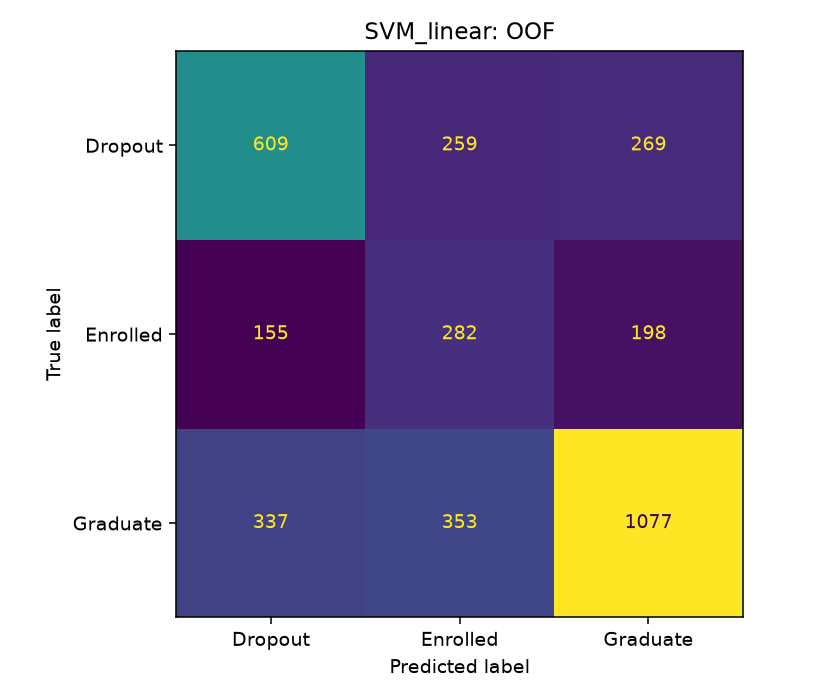

RandomForest


,precision,recall,f1-score,support
Dropout,0.5566,0.5488,0.5527,1137.0000
Enrolled,0.3075,0.4000,0.3477,635.0000
Graduate,0.7004,0.6310,0.6639,1767.0000
accuracy,0.5632,0.5632,0.5632,0.5632
macro avg,0.5215,0.5266,0.5214,3539.0000
weighted avg,0.5837,0.5632,0.5714,3539.0000


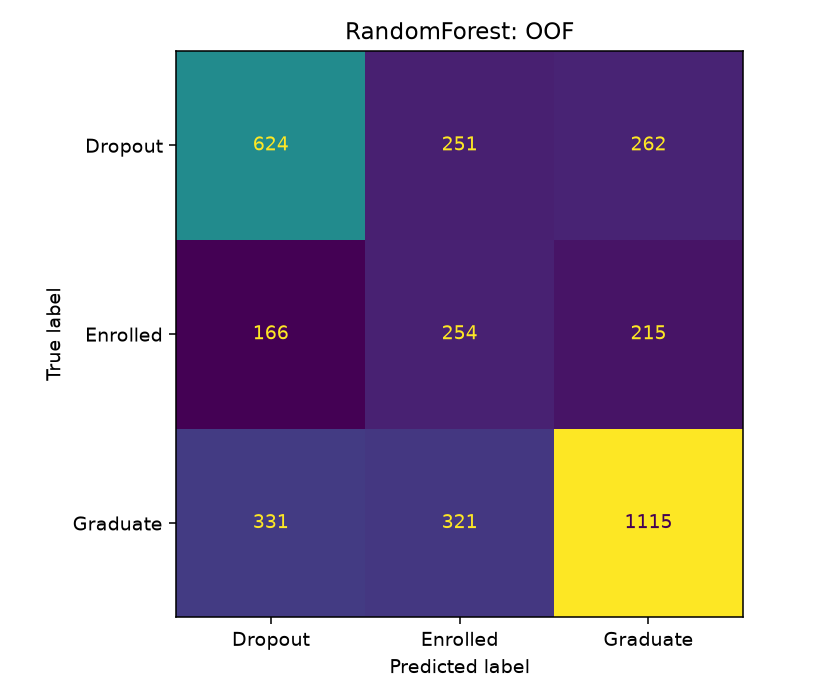

SVM_rbf


,precision,recall,f1-score,support
Dropout,0.5566,0.5233,0.5394,1137.0000
Enrolled,0.3076,0.4457,0.3640,635.0000
Graduate,0.6968,0.6112,0.6512,1767.0000
accuracy,0.5533,0.5533,0.5533,0.5533
macro avg,0.5203,0.5267,0.5182,3539.0000
weighted avg,0.5819,0.5533,0.5638,3539.0000


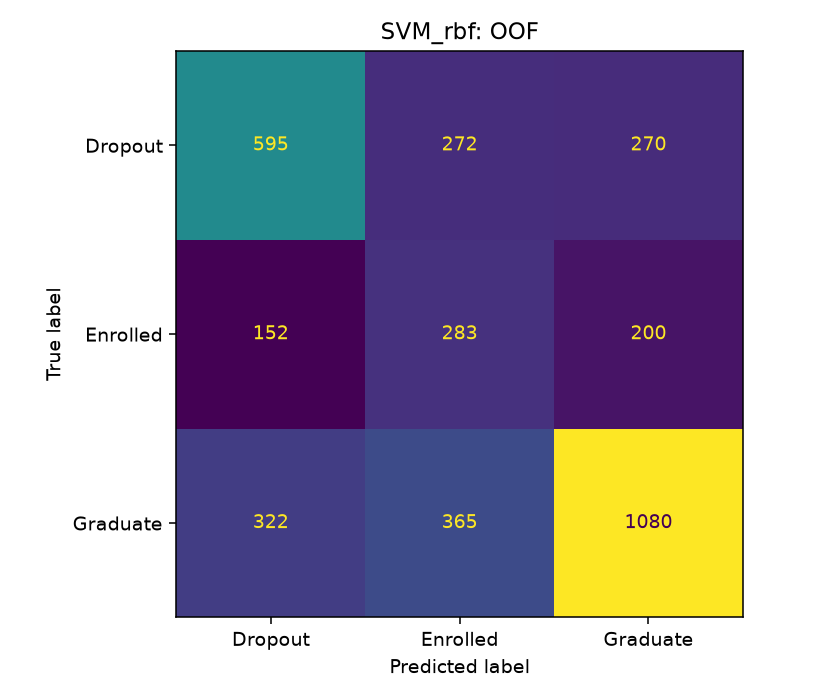

LogisticRegression


,precision,recall,f1-score,support
Dropout,0.5517,0.5259,0.5385,1137.0000
Enrolled,0.3065,0.4551,0.3663,635.0000
Graduate,0.6997,0.5988,0.6453,1767.0000
accuracy,0.5496,0.5496,0.5496,0.5496
macro avg,0.5193,0.5266,0.5167,3539.0000
weighted avg,0.5816,0.5496,0.5609,3539.0000


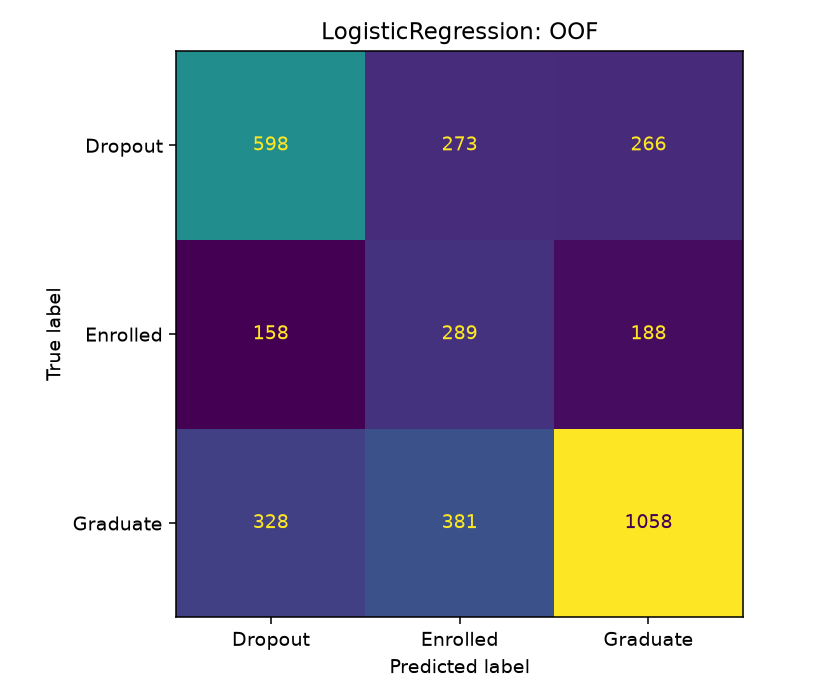

CategoricalNB


,precision,recall,f1-score,support
Dropout,0.5775,0.5242,0.5496,1137.0000
Enrolled,0.3795,0.1984,0.2606,635.0000
Graduate,0.6239,0.7680,0.6885,1767.0000
accuracy,0.5875,0.5875,0.5875,0.5875
macro avg,0.5270,0.4969,0.4995,3539.0000
weighted avg,0.5652,0.5875,0.5671,3539.0000


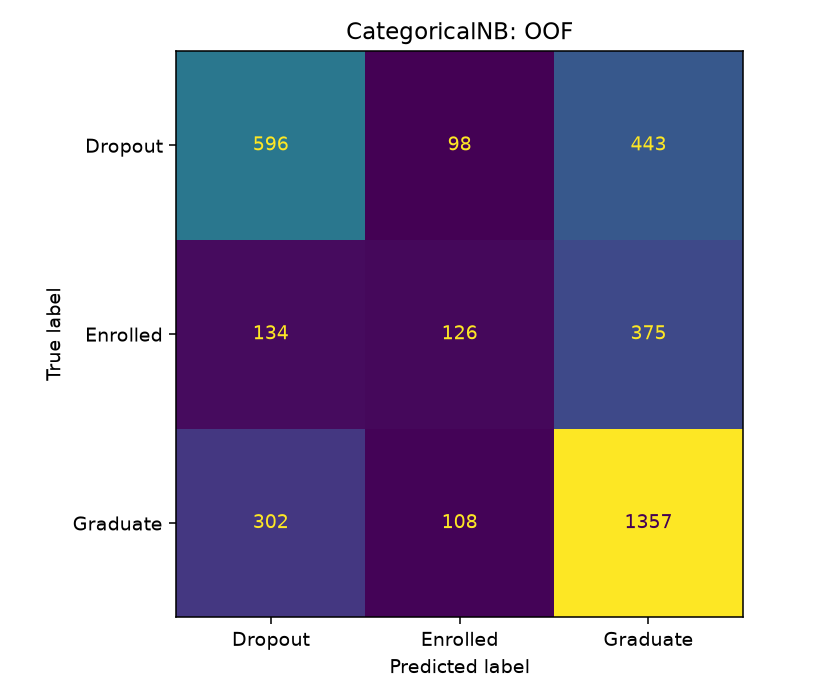

LightGBM


,precision,recall,f1-score,support
Dropout,0.5475,0.5268,0.5370,1137.0000
Enrolled,0.3755,0.1354,0.1991,635.0000
Graduate,0.6345,0.7957,0.7060,1767.0000
accuracy,0.5908,0.5908,0.5908,0.5908
macro avg,0.5192,0.4860,0.4807,3539.0000
weighted avg,0.5601,0.5908,0.5607,3539.0000


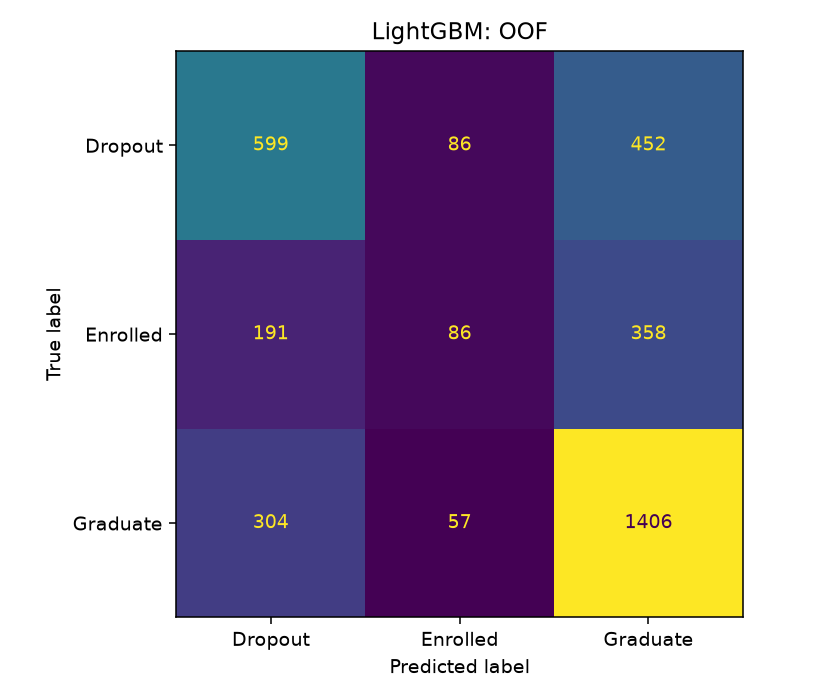

XGBoost


,precision,recall,f1-score,support
Dropout,0.5718,0.5251,0.5475,1137.0000
Enrolled,0.4397,0.0976,0.1598,635.0000
Graduate,0.6240,0.8314,0.7129,1767.0000
accuracy,0.6013,0.6013,0.6013,0.6013
macro avg,0.5452,0.4847,0.4734,3539.0000
weighted avg,0.5742,0.6013,0.5605,3539.0000


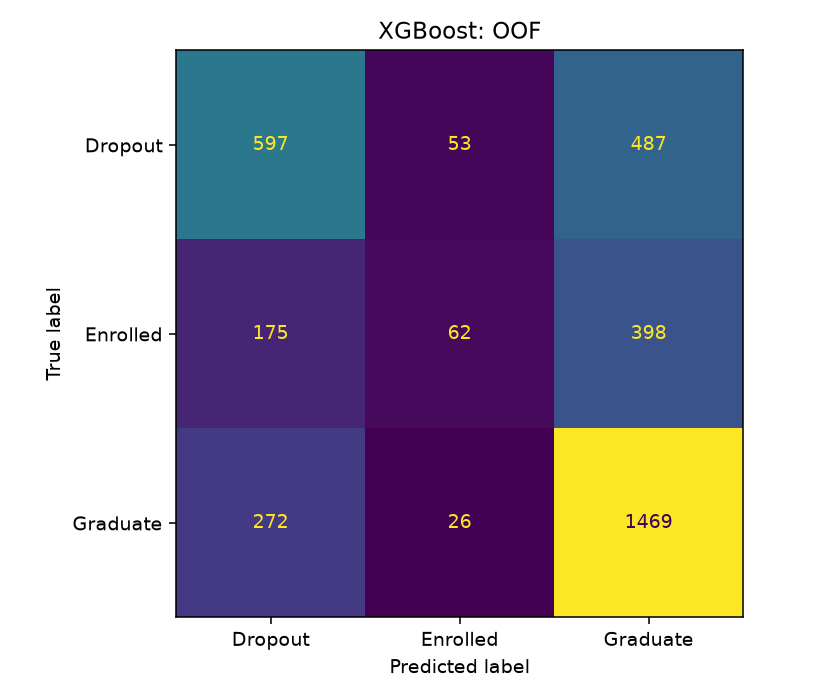

GradientBoosting


,precision,recall,f1-score,support
Dropout,0.5847,0.5040,0.5413,1137.0000
Enrolled,0.4472,0.0866,0.1451,635.0000
Graduate,0.6133,0.8455,0.7109,1767.0000
accuracy,0.5996,0.5996,0.5996,0.5996
macro avg,0.5484,0.4787,0.4658,3539.0000
weighted avg,0.5743,0.5996,0.5549,3539.0000


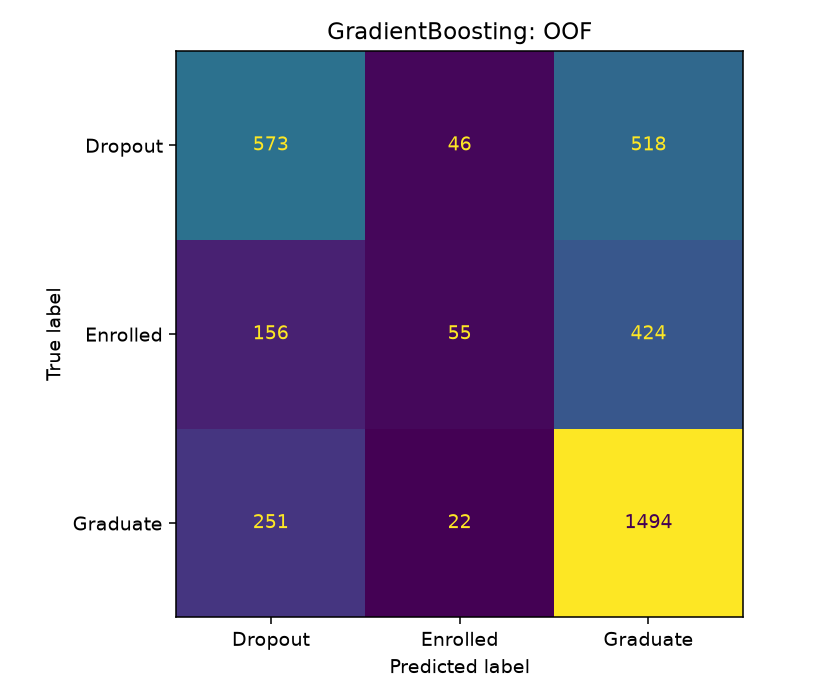

CatBoost


,precision,recall,f1-score,support
Dropout,0.5682,0.5277,0.5472,1137.0000
Enrolled,0.4928,0.0535,0.0966,635.0000
Graduate,0.6147,0.8398,0.7099,1767.0000
accuracy,0.5985,0.5985,0.5985,0.5985
macro avg,0.5586,0.4737,0.4512,3539.0000
weighted avg,0.5779,0.5985,0.5476,3539.0000


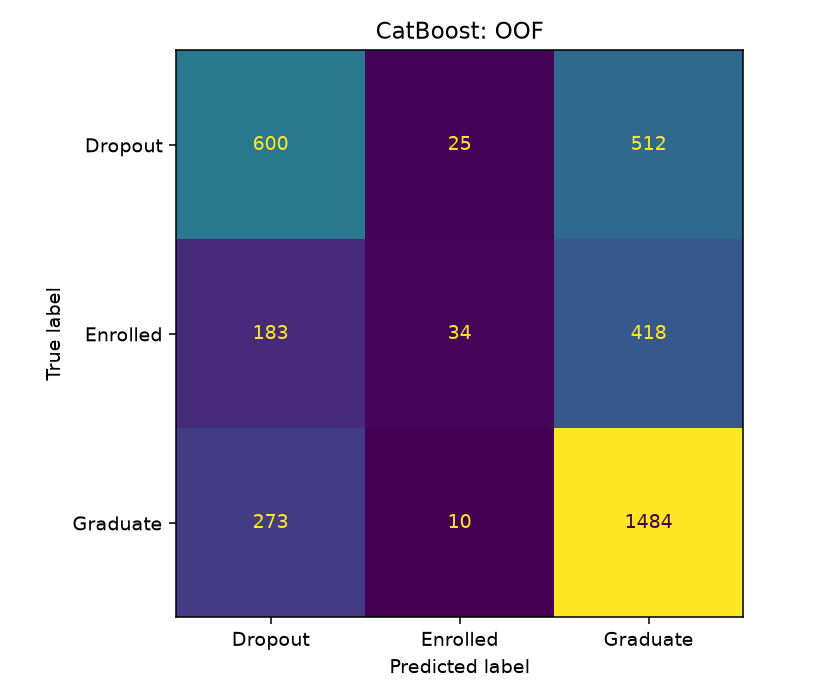

DecisionTree


,precision,recall,f1-score,support
Dropout,0.5483,0.4046,0.4656,1137.0000
Enrolled,0.2286,0.5591,0.3245,635.0000
Graduate,0.6896,0.4477,0.5429,1767.0000
accuracy,0.4538,0.4538,0.4538,0.4538
macro avg,0.4888,0.4704,0.4443,3539.0000
weighted avg,0.5615,0.4538,0.4789,3539.0000


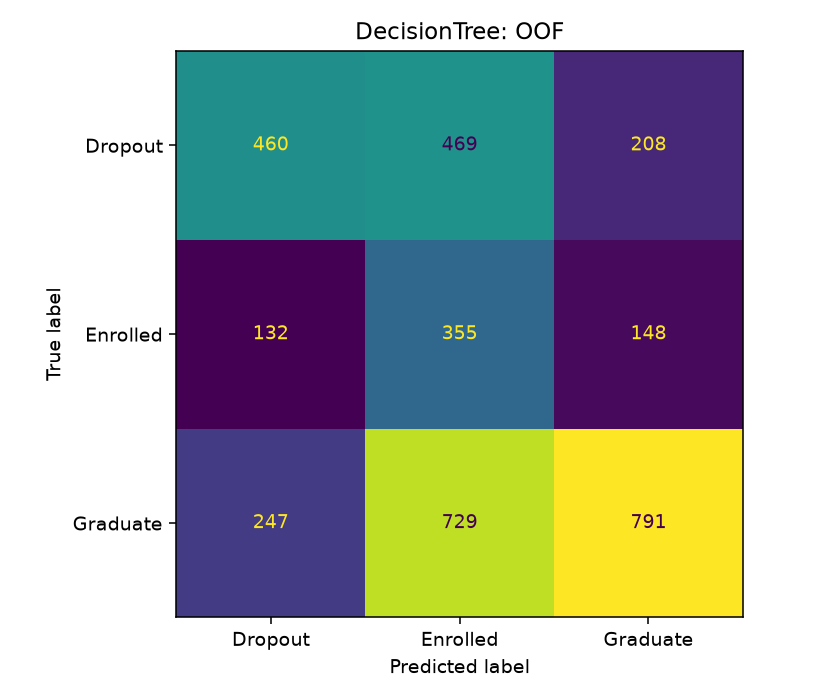

Dummy


,precision,recall,f1-score,support
Dropout,0.0000,0.0000,0.0000,1137.0000
Enrolled,0.0000,0.0000,0.0000,635.0000
Graduate,0.4993,1.0000,0.6660,1767.0000
accuracy,0.4993,0.4993,0.4993,0.4993
macro avg,0.1664,0.3333,0.2220,3539.0000
weighted avg,0.2493,0.4993,0.3325,3539.0000


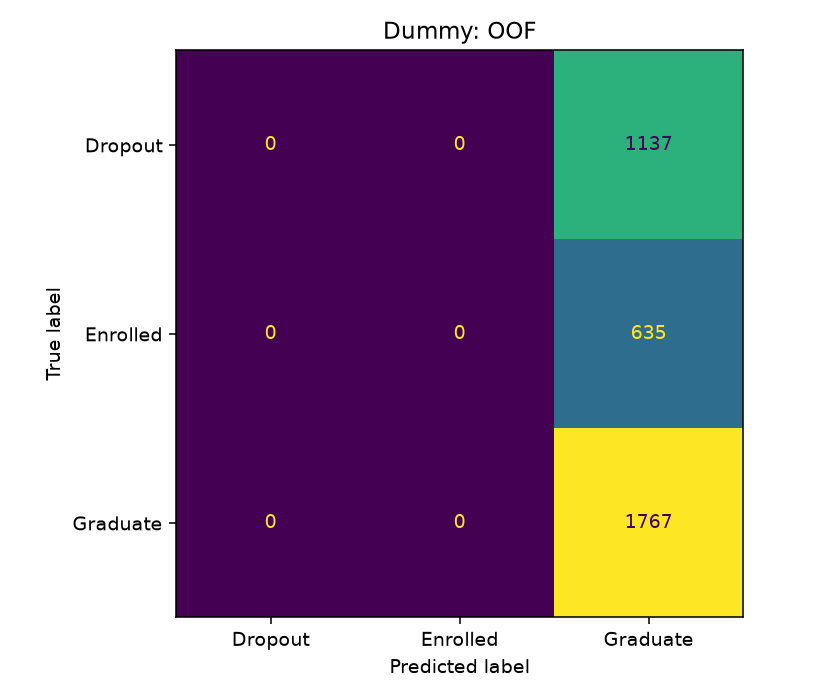

In [11]:
for name in comparison["model"]:
    result = json.loads((OUTPUT_DIR / f"{name}_oof.json").read_text())
    print(name)
    display(pd.DataFrame(result["report"]).T.round(4))
    display(Image(filename=str(OUTPUT_DIR / f"{name}_oof.png")))

#### 11. Выбранная модель и исторический holdout

{'winner': 'SVM_linear', 'criterion': 'mean CV macro F1'}


macro_f1             0.489207
weighted_f1          0.537518
balanced_accuracy    0.494064
accuracy             0.528814
dtype: float64

,precision,recall,f1-score,support
Dropout,0.5347,0.5423,0.5385,284.0000
Enrolled,0.2740,0.3585,0.3106,159.0000
Graduate,0.6607,0.5814,0.6185,442.0000
accuracy,0.5288,0.5288,0.5288,0.5288
macro avg,0.4898,0.4941,0.4892,885.0000
weighted avg,0.5508,0.5288,0.5375,885.0000


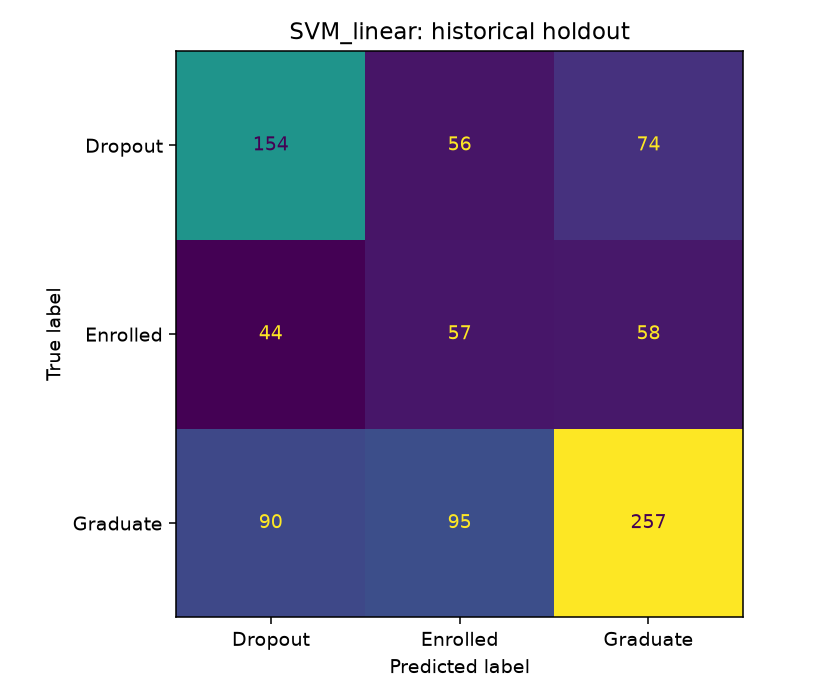

Пропущено Dropout: 130
Ложные сигналы Dropout: 134


In [12]:
selection = json.loads((OUTPUT_DIR / "selection.json").read_text())
result = json.loads((OUTPUT_DIR / "test_metrics.json").read_text())
print(selection)
display(pd.Series({k: v for k, v in result.items() if k not in {"report", "confusion_matrix"}}))
display(pd.DataFrame(result["report"]).T.round(4))
display(Image(filename=str(OUTPUT_DIR / "test_confusion.png")))
cm = np.asarray(result["confusion_matrix"])
print("Пропущено Dropout:", int(cm[0].sum() - cm[0, 0]))
print("Ложные сигналы Dropout:", int(cm[:, 0].sum() - cm[0, 0]))

#### 12. Ограничения и следующий этап
Enrolled означает, что обучение ещё продолжается к моменту фиксации исхода; это не гарантированный будущий Graduate или Dropout. Случайный split не проверяет перенос на другую когорту или вуз; CSV не содержит временных меток и идентификаторов студентов. Нужен перспективный тест на новой когорте с проверкой доступности каждого признака.  

Пол, гражданство, возраст, особые потребности и семейные признаки могут воспроизводить неравенство. Удаление этих полей само по себе не устраняет его: другие поля бывают прокси. Перед практическим применением нужны групповые precision/recall, оценка неопределённости, проверка качества данных и правомерности обработки, возможность исправить данные и отказаться от контакта. Здесь fairness-аудит и калибровка вероятностей не выполнены.  

Назначение - предложить добровольную поддержку с участием человека. Нельзя делать автоматические санкции, отказывать в образовании, ранжировать «ценности» студента или решать его судьбу, ведь это просто прогноз (не диагноз и не объяснение причин). Ошибка Graduate → Dropout создаёт ложную тревогу, Dropout → Graduate/Enrolled — пропущенное предложение поддержки.  

В проекте функции из разделов 1–8 становятся отдельными модулями.